# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Dista Ishlahul Amalia
- **Email:** distawealthy01@gmail.com
- **ID Dicoding:** DS284B6X1868

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

- **Pertanyaan 1:** Kategori produk apa yang menghasilkan total revenue tertinggi, dan bagaimana tren revenue bulanan dari September 2016 hingga Agustus 2017 berdasarkan pesanan yang berstatus delivered?
- **Pertanyaan 2:** Seberapa besar perbedaan rata-rata review score antara pesanan yang terlambat dan tepat waktu, berdasarkan perbandingan tanggal pengiriman aktual dengan tanggal estimasi, pada pesanan yang dibeli selama Januari–Desember 2017?

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style='whitegrid')

## Data Wrangling

### Gathering Data

#### Load df orders

In [2]:
orders_df = pd.read_csv('data/orders_dataset.csv')

orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


#### Load df order_items

In [3]:
order_items_df = pd.read_csv('data/order_items_dataset.csv')

order_items_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


#### Load df order_payments

In [4]:
order_payments_df = pd.read_csv('data/order_payments_dataset.csv')

order_payments_df.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


#### Load df order_reviews

In [5]:
order_reviews_df = pd.read_csv('data/order_reviews_dataset.csv')

order_reviews_df.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


#### Load df customers

In [6]:
customers_df = pd.read_csv('data/customers_dataset.csv')

customers_df.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


#### Load df products

In [7]:
products_df = pd.read_csv('data/products_dataset.csv')

products_df.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


#### Load df product_category_name_translation

In [8]:
category_translation_df = pd.read_csv('data/product_category_name_translation.csv')

category_translation_df.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


**Insight:** (Opsional)

- Proyek ini menggunakan tujuh dataset, yaitu orders, order items, order payments, order reviews, customers, products, dan product category name translation. Dataset tersebut menyediakan informasi mengenai transaksi, produk, pembayaran, pelanggan, ulasan, serta kategori produk.
- Penggabungan dataset berdasarkan kolom kunci seperti `order_id`, `customer_id`, dan `product_id` memungkinkan analisis revenue per kategori produk serta perbandingan review score berdasarkan ketepatan pengiriman. Data pesanan dan pembayaran juga digunakan untuk analisis lanjutan RFM.
- Setiap dataset memiliki fungsi yang berbeda sehingga pemeriksaan kualitas data perlu dilakukan sebelum penggabungan. Tahap ini penting untuk mengurangi risiko kesalahan analisis akibat missing value, ketidaksesuaian tipe data, atau data yang tidak lengkap.

### Assessing Data

#### Identifying orders_df problem

In [9]:
orders_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB


In [10]:
orders_df.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [11]:
print("Jumlah duplikasi: ", orders_df.duplicated().sum())

Jumlah duplikasi:  0


In [12]:
orders_df.describe()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,98875,90733,81018,95664,459
top,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2018-03-31 15:08:21,2018-02-27 04:31:10,2018-05-09 15:48:00,2018-05-14 20:02:44,2017-12-20 00:00:00
freq,1,1,96478,3,9,47,3,522


#### Identifying order_items_df problem

In [13]:
order_items_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 18.4 MB


In [14]:
order_items_df.isna().sum()

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

In [15]:
print("Jumlah duplikasi: ", order_items_df.duplicated().sum())

Jumlah duplikasi:  0


In [16]:
order_items_df.describe()

,order_item_id,price,freight_value
count,112650.000000,112650.000000,112650.000000
mean,1.197834,120.653739,19.990320
std,0.705124,183.633928,15.806405
min,1.000000,0.850000,0.000000
25%,1.000000,39.900000,13.080000
50%,1.000000,74.990000,16.260000
75%,1.000000,134.900000,21.150000
max,21.000000,6735.000000,409.680000


#### Identifying order_payments_df problem

In [17]:
order_payments_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  str    
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  str    
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), str(2)
memory usage: 8.1 MB


In [18]:
order_payments_df.isna().sum()

order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

In [19]:
print("Jumlah duplikasi: ", order_payments_df.duplicated().sum())

Jumlah duplikasi:  0


#### Identifying order_reviews_df problem

In [20]:
order_reviews_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   review_id                99224 non-null  str  
 1   order_id                 99224 non-null  str  
 2   review_score             99224 non-null  int64
 3   review_comment_title     11568 non-null  str  
 4   review_comment_message   40977 non-null  str  
 5   review_creation_date     99224 non-null  str  
 6   review_answer_timestamp  99224 non-null  str  
dtypes: int64(1), str(6)
memory usage: 17.8 MB


In [21]:
order_reviews_df.isna().sum()

review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

#### Identifying products_df problem

In [22]:
products_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  str    
 1   product_category_name       32341 non-null  str    
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), str(2)
memory usage: 3.7 MB


In [24]:
products_df.isna().sum()

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

#### Identifying customers_df problem

In [25]:
customers_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 11.0 MB


In [26]:
customers_df.isna().sum()

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

In [27]:
print("Jumlah duplikasi: ", customers_df.duplicated().sum())

Jumlah duplikasi:  0


**Steps to Take:**

- Mengidentifikasi missing value pada setiap dataset dan menentukan penanganannya berdasarkan fungsi masing-masing kolom. Missing value pada tanggal persetujuan atau pengiriman pesanan tidak boleh langsung diisi dengan nilai sembarang karena dapat merepresentasikan proses pesanan yang belum terjadi atau belum tercatat.
- Memeriksa duplikasi data pada dataset utama untuk memastikan bahwa proses penggabungan dan agregasi tidak dipengaruhi oleh baris yang berulang.
- Memeriksa tipe data kolom tanggal pada `orders_df` dan mengubahnya menjadi tipe datetime agar dapat digunakan untuk menghitung selisih antara tanggal pengiriman aktual dan tanggal estimasi.
- Menangani produk yang tidak memiliki kategori pada tahap cleaning karena informasi kategori diperlukan untuk menghitung dan membandingkan revenue antarkategori produk.
- Mempertahankan missing value pada kolom komentar ulasan karena analisis kepuasan pelanggan menggunakan `review_score`, bukan teks komentar.

**Insight:** (Opsional)

- Pada `orders_df`, ditemukan 160 missing value pada `order_approved_at`, 1.783 pada `order_delivered_carrier_date`, dan 2.965 pada `order_delivered_customer_date`. Nilai yang hilang pada kolom waktu pengiriman perlu diperhatikan karena dapat memengaruhi analisis ketepatan pengiriman.
- Pada `order_reviews_df`, terdapat 87.656 missing value pada `review_comment_title` dan 58.247 pada `review_comment_message`. Missing value tersebut tidak menghalangi analisis rata-rata review score karena skor ulasan tetap tersedia.
- Pada `products_df`, terdapat 610 produk tanpa `product_category_name`. Kondisi ini dapat menghambat pengelompokan revenue berdasarkan kategori sehingga perlu ditangani pada tahap cleaning.
- Pemeriksaan duplikasi menunjukkan tidak ditemukan baris duplikat pada dataset utama yang diperiksa. Oleh karena itu, penghapusan duplikasi tidak diperlukan berdasarkan hasil pemeriksaan tersebut.
- Temuan assessment menunjukkan bahwa penanganan data perlu disesuaikan dengan kebutuhan analisis. Tidak semua missing value harus dihapus atau diisi, terutama jika kolom tersebut tidak digunakan dalam pertanyaan bisnis.

### Cleaning Data

#### Fixing datetime columns in orders_df

In [28]:
datetime_cols = ['order_purchase_timestamp', 'order_approved_at',
                  'order_delivered_carrier_date', 'order_delivered_customer_date',
                  'order_estimated_delivery_date']

for col in datetime_cols:
    orders_df[col] = pd.to_datetime(orders_df[col])

orders_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_approved_at              99281 non-null  datetime64[us]
 5   order_delivered_carrier_date   97658 non-null  datetime64[us]
 6   order_delivered_customer_date  96476 non-null  datetime64[us]
 7   order_estimated_delivery_date  99441 non-null  datetime64[us]
dtypes: datetime64[us](5), str(3)
memory usage: 13.0 MB


#### Fixing missing category in products_df

In [29]:
products_clean_df = products_df.dropna(subset=['product_category_name']).copy()

print("Jumlah baris sebelum:", len(products_df))
print("Jumlah baris sesudah:", len(products_clean_df))
products_clean_df.isna().sum()

Jumlah baris sebelum: 32951
Jumlah baris sesudah: 32341


product_id                    0
product_category_name         0
product_name_lenght           0
product_description_lenght    0
product_photos_qty            0
product_weight_g              1
product_length_cm             1
product_height_cm             1
product_width_cm              1
dtype: int64

**Insight:** (Opsional)

- Kolom waktu pada `orders_df` dikonversi menjadi tipe datetime agar perhitungan selisih tanggal pengiriman aktual dan tanggal estimasi dapat dilakukan dengan benar.
- Dataset produk awal berisi 32.951 baris. Sebanyak 610 baris tidak memiliki kategori produk sehingga dikeluarkan dari `products_clean_df`, menyisakan 32.341 produk dengan kategori yang tersedia.
- Missing value pada atribut fisik produk, seperti berat dan dimensi, masih dapat ditemukan setelah pembersihan kategori. Atribut tersebut tidak digunakan untuk menjawab dua pertanyaan bisnis utama sehingga tidak dilakukan imputasi dalam analisis ini.
- Penanganan data dilakukan sesuai kebutuhan analisis, bukan dengan menghapus seluruh baris yang mengandung missing value. Pendekatan ini membantu mempertahankan data yang masih relevan untuk analisis revenue dan kepuasan pelanggan.

## Exploratory Data Analysis (EDA)

### Explore kategori produk dan revenue

In [30]:
order_items_cat_df = order_items_df.merge(
    products_clean_df[['product_id', 'product_category_name']],
    on='product_id', how='inner'
).merge(
    category_translation_df, on='product_category_name', how='left'
)

order_items_cat_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_category_name_english
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,garden_tools


In [31]:
sales_df = order_items_cat_df.merge(
    orders_df[['order_id', 'order_purchase_timestamp', 'order_status']],
    on='order_id', how='inner'
)

sales_df = sales_df[
    (sales_df['order_purchase_timestamp'] >= '2016-09-01') &
    (sales_df['order_purchase_timestamp'] < '2017-09-01') &
    (sales_df['order_status'] == 'delivered')
]

sales_df.shape

(24779, 11)

**Definisi Revenue**

Dalam analisis ini, revenue dihitung dengan menjumlahkan kolom price pada dataset item pesanan yang berstatus delivered. Nilai tersebut merepresentasikan total harga produk yang tercatat pada item pesanan dan tidak memasukkan ongkos kirim (freight_value) maupun komponen pembayaran lainnya. Oleh karena itu, hasil analisis digunakan untuk membandingkan kontribusi harga produk antarkategori, bukan sebagai total seluruh pembayaran pelanggan.

In [32]:
revenue_per_category = sales_df.groupby('product_category_name_english')['price'].sum().sort_values(ascending=False)
revenue_per_category.head(10)

product_category_name_english
bed_bath_table           254923.81
health_beauty            247095.92
sports_leisure           218736.48
computers_accessories    215300.29
cool_stuff               207352.47
watches_gifts            203848.93
furniture_decor          176549.10
garden_tools             139411.03
housewares               128821.61
perfumery                126782.46
Name: price, dtype: float64

In [33]:
monthly_revenue = sales_df.set_index('order_purchase_timestamp').resample('ME')['price'].sum()
monthly_revenue

order_purchase_timestamp
2016-09-30       134.97
2016-10-31     40259.22
2016-11-30         0.00
2016-12-31        10.90
2017-01-31    110194.72
2017-02-28    225702.29
2017-03-31    352741.68
2017-04-30    332221.49
2017-05-31    478519.91
2017-06-30    417020.97
2017-07-31    478636.66
2017-08-31    549731.25
Freq: ME, Name: price, dtype: float64

### Explore status pesanan dan ketepatan pengiriman

In [34]:
orders_df['order_status'].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [35]:
delivery_df = orders_df[orders_df['order_status'] == 'delivered'].copy()
delivery_df = delivery_df.dropna(subset=['order_delivered_customer_date', 'order_estimated_delivery_date'])

delivery_df = delivery_df[
    (delivery_df['order_purchase_timestamp'] >= '2017-01-01') &
    (delivery_df['order_purchase_timestamp'] < '2018-01-01')
]

delivery_df['delay_days'] = (
    delivery_df['order_delivered_customer_date'] - delivery_df['order_estimated_delivery_date']
).dt.days
delivery_df['is_late'] = delivery_df['delay_days'] > 0

delivery_df[['delay_days', 'is_late']].describe(include='all')

,delay_days,is_late
count,43426.000000,43426
unique,NaN,2
top,NaN,False
freq,NaN,40973
mean,-12.334730,NaN
std,9.952188,NaN
min,-140.000000,NaN
25%,-17.000000,NaN
50%,-13.000000,NaN
75%,-8.000000,NaN


In [36]:
delivery_review_df = delivery_df.merge(
    order_reviews_df[['order_id', 'review_score']], on='order_id', how='left'
).dropna(subset=['review_score'])

delivery_review_df.shape

(43415, 11)

In [37]:
delivery_review_df.groupby('is_late')['review_score'].agg(['mean', 'count'])

,mean,count
is_late,,
False,4.282113,41019
True,2.319282,2396


**Insight:** (Opsional)

- Berdasarkan data pesanan delivered pada periode September 2016–Agustus 2017, kategori `bed_bath_table` menghasilkan revenue tertinggi sebesar BRL 254.923,81. Kategori berikutnya adalah `health_beauty` sebesar BRL 247.095,92 dan `sports_leisure` sebesar BRL 218.736,48.
- Revenue bulanan mencapai BRL 549.731,25 pada Agustus 2017, nilai tertinggi dalam periode yang dianalisis. Revenue juga meningkat dari awal 2017 menuju pertengahan tahun, meskipun terdapat fluktuasi antarb​​ulan. Hasil ini dapat menjadi bahan pertimbangan dalam perencanaan stok dan promosi.
- Analisis ketepatan pengiriman menggunakan pesanan delivered yang dibeli sepanjang 2017 dan memiliki tanggal pengiriman aktual serta estimasi. Setelah digabungkan dengan data review, terdapat 43.415 pesanan dengan review score yang dapat dianalisis.
- Dari pesanan yang memiliki review score tersebut, 41.019 pesanan dikirim tepat waktu dan 2.396 pesanan terlambat. Rata-rata review score pesanan tepat waktu adalah 4,28, sedangkan pesanan terlambat memiliki rata-rata 2,32.
- Perbedaan rata-rata review score sebesar sekitar 1,96 poin menunjukkan bahwa pesanan terlambat berkaitan dengan penilaian pelanggan yang lebih rendah secara deskriptif. Namun, hasil ini tidak dengan sendirinya membuktikan bahwa keterlambatan merupakan satu-satunya penyebab rendahnya review score.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori produk dan tren penjualan

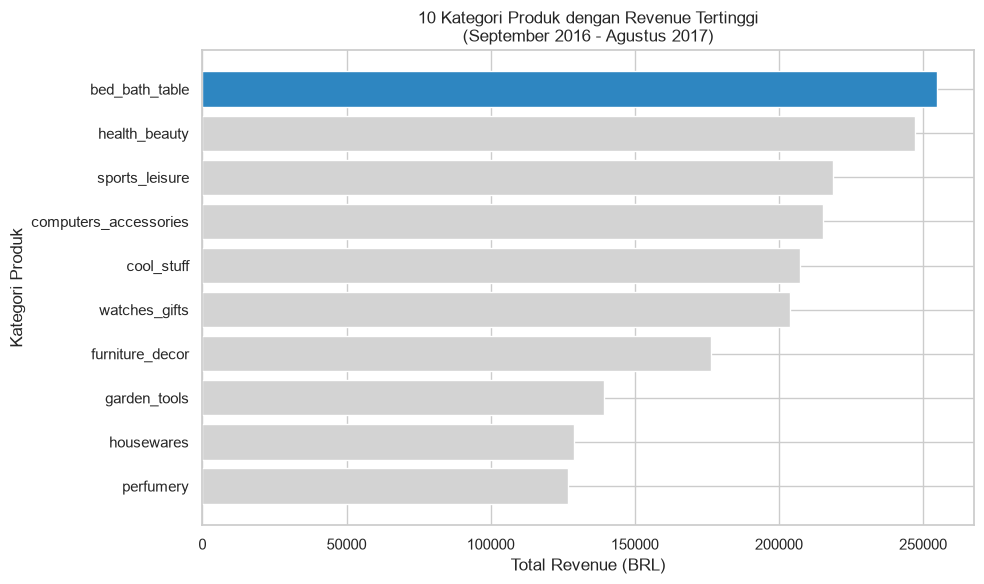

In [38]:
top10 = revenue_per_category.head(10)
colors = ['#D3D3D3'] * len(top10)
colors[0] = '#2E86C1'  # highlight kategori tertinggi

plt.figure(figsize=(10, 6))
plt.barh(top10.index[::-1], top10.values[::-1], color=colors[::-1])
plt.xlabel('Total Revenue (BRL)')
plt.ylabel('Kategori Produk')
plt.title('10 Kategori Produk dengan Revenue Tertinggi\n(September 2016 - Agustus 2017)')
plt.tight_layout()
plt.show()

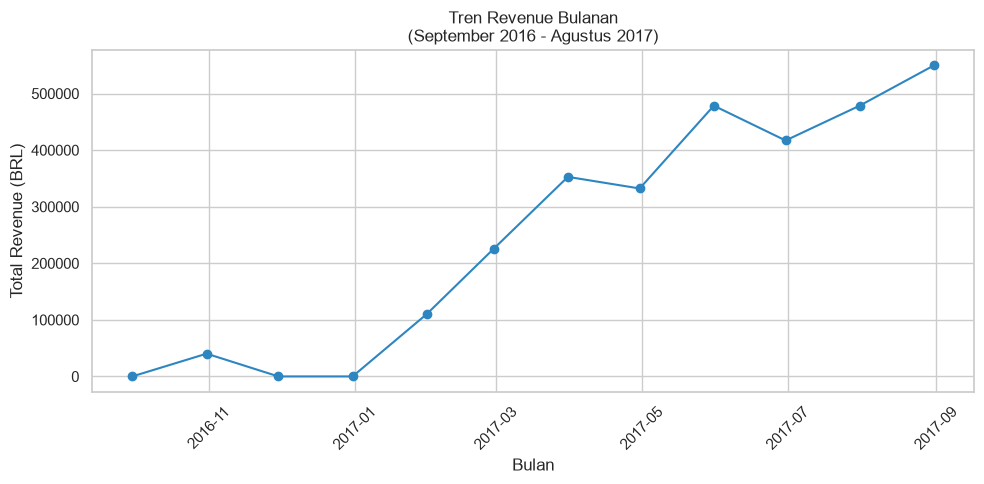

In [39]:
plt.figure(figsize=(10, 5))
plt.plot(monthly_revenue.index, monthly_revenue.values, marker='o', color='#2E86C1')
plt.title('Tren Revenue Bulanan\n(September 2016 - Agustus 2017)')
plt.xlabel('Bulan')
plt.ylabel('Total Revenue (BRL)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Pertanyaan 2: Keterlambatan pengiriman dan review score

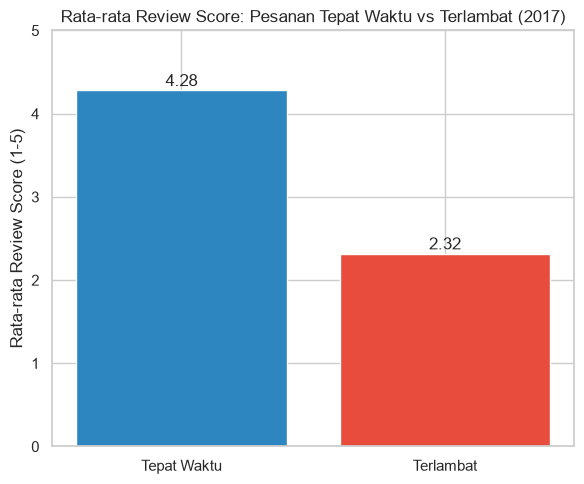

In [40]:
avg_review = delivery_review_df.groupby('is_late')['review_score'].mean()
avg_review.index = ['Tepat Waktu', 'Terlambat']

plt.figure(figsize=(6, 5))
bars = plt.bar(avg_review.index, avg_review.values, color=['#2E86C1', '#E74C3C'])
plt.title('Rata-rata Review Score: Pesanan Tepat Waktu vs Terlambat (2017)')
plt.ylabel('Rata-rata Review Score (1-5)')
plt.ylim(0, 5)
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.05, f'{height:.2f}', ha='center')
plt.tight_layout()
plt.show()

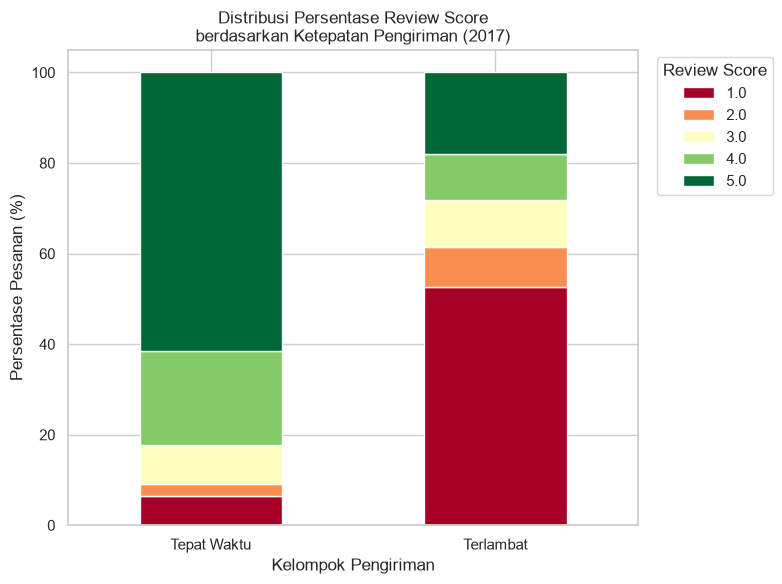

In [41]:
pivot = delivery_review_df.groupby(['is_late', 'review_score']).size().unstack(fill_value=0)
pivot.index = ['Tepat Waktu', 'Terlambat']
pivot_pct = pivot.div(pivot.sum(axis=1), axis=0) * 100

pivot_pct.plot(kind='bar', stacked=True, figsize=(8, 6), colormap='RdYlGn')
plt.title('Distribusi Persentase Review Score\nberdasarkan Ketepatan Pengiriman (2017)')
plt.xlabel('Kelompok Pengiriman')
plt.ylabel('Persentase Pesanan (%)')
plt.xticks(rotation=0)
plt.legend(title='Review Score', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Insight:** (Opsional)

- Grafik 10 kategori produk dengan revenue tertinggi memperlihatkan bahwa `bed_bath_table` berada pada peringkat pertama dengan revenue BRL 254.923,81, diikuti `health_beauty` dan `sports_leisure`. Ketiga kategori tersebut dapat menjadi prioritas evaluasi stok dan strategi pemasaran.
- Grafik tren revenue bulanan menunjukkan bahwa revenue tertinggi tercatat pada Agustus 2017 sebesar BRL 549.731,25. Pola peningkatan pada beberapa bulan di 2017 dapat menjadi masukan untuk perencanaan operasional, tetapi perlu dipertimbangkan bahwa jumlah transaksi dan kelengkapan data pada setiap bulan dapat berbeda.
- Grafik perbandingan rata-rata review score memperlihatkan nilai 4,28 untuk pesanan tepat waktu dan 2,32 untuk pesanan terlambat. Selisih ini menunjukkan perbedaan penilaian pelanggan yang cukup besar antara kedua kelompok.
- Grafik distribusi persentase review score membantu melihat bahwa perbandingan tidak hanya berkaitan dengan rata-rata, tetapi juga dengan komposisi skor ulasan pada masing-masing kelompok pengiriman.
- Secara keseluruhan, visualisasi menjawab kedua pertanyaan bisnis: kategori mana yang menghasilkan revenue tertinggi dan bagaimana pola revenue bulanan, serta bagaimana review score berbeda berdasarkan ketepatan pengiriman.

## Analisis Lanjutan: RFM Analysis

RFM (Recency, Frequency, Monetary) Analysis digunakan untuk mengelompokkan pelanggan berdasarkan perilaku transaksi mereka tanpa menggunakan algoritma machine learning, murni berdasarkan agregasi dan scoring manual. Teknik ini dipilih karena relevan untuk menjawab kebutuhan bisnis e-commerce dalam mengidentifikasi pelanggan paling bernilai (loyal/champion) versus pelanggan yang berisiko churn, sehingga strategi retensi dapat lebih tepat sasaran.

- **Recency:** jumlah hari sejak transaksi terakhir pelanggan.
- **Frequency:** jumlah pesanan unik yang pernah dilakukan pelanggan.
- **Monetary:** total nilai pembayaran yang pernah dikeluarkan pelanggan.

In [42]:
payments_per_order = order_payments_df.groupby('order_id')['payment_value'].sum().reset_index()

rfm_base_df = orders_df[orders_df['order_status'] == 'delivered'].merge(
    customers_df[['customer_id', 'customer_unique_id']], on='customer_id'
).merge(
    payments_per_order, on='order_id'
)

snapshot_date = rfm_base_df['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

rfm_df = rfm_base_df.groupby('customer_unique_id').agg(
    last_purchase_date=('order_purchase_timestamp', 'max'),
    frequency=('order_id', 'nunique'),
    monetary=('payment_value', 'sum')
).reset_index()

rfm_df['recency'] = (snapshot_date - rfm_df['last_purchase_date']).dt.days

rfm_df[['recency', 'frequency', 'monetary']].describe()

,recency,frequency,monetary
count,93357.000000,93357.000000,93357.000000
mean,237.936673,1.033420,165.198772
std,152.584315,0.209099,226.314579
min,1.000000,1.000000,9.590000
25%,114.000000,1.000000,63.060000
50%,219.000000,1.000000,107.780000
75%,346.000000,1.000000,182.560000
max,695.000000,15.000000,13664.080000


**Interpretasi Statistik RFM**

Berdasarkan hasil perhitungan RFM, terdapat 93.357 pelanggan unik yang memiliki pesanan berstatus *delivered*. Nilai rata-rata Recency sebesar 237,94 hari menunjukkan bahwa jarak waktu antara transaksi terakhir pelanggan dan tanggal acuan dalam dataset rata-rata sekitar 238 hari. Sementara itu, nilai median Recency sebesar 219 hari menunjukkan bahwa separuh pelanggan memiliki jarak waktu sejak transaksi terakhir tidak lebih dari 219 hari.

Pada metrik Frequency, rata-rata sebesar 1,03 transaksi dan median sebesar 1 transaksi menunjukkan bahwa sebagian besar pelanggan hanya melakukan satu transaksi dalam data yang dianalisis. Meskipun demikian, terdapat pelanggan dengan frekuensi pembelian hingga 15 transaksi.

Pada metrik Monetary, rata-rata pengeluaran tercatat sebesar BRL 165,20, sedangkan mediannya sebesar BRL 107,78. Rata-rata yang lebih tinggi daripada median menunjukkan bahwa distribusi nilai pembayaran cenderung memiliki sejumlah pelanggan dengan total pembayaran jauh lebih besar daripada pelanggan pada umumnya.

Hasil ini memberikan gambaran awal mengenai perilaku pembelian pelanggan. Namun, statistik deskriptif belum cukup untuk menentukan kelompok pelanggan yang perlu diprioritaskan. Oleh karena itu, analisis dilanjutkan dengan pemberian skor RFM dan pengelompokan pelanggan berdasarkan kombinasi Recency, Frequency, dan Monetary. Perlu diperhatikan bahwa nilai Monetary pada analisis ini hanya mencakup pembayaran dari pesanan yang berstatus *delivered*.

In [43]:
rfm_df['r_score'] = pd.qcut(rfm_df['recency'], 4, labels=[4, 3, 2, 1]).astype(int)
rfm_df['f_score'] = rfm_df['frequency'].apply(lambda x: 4 if x >= 4 else (3 if x == 3 else (2 if x == 2 else 1)))
rfm_df['m_score'] = pd.qcut(rfm_df['monetary'].rank(method='first'), 4, labels=[1, 2, 3, 4]).astype(int)

rfm_df['rfm_score'] = rfm_df['r_score'] + rfm_df['f_score'] + rfm_df['m_score']

def segment_customer(score):
    if score >= 10:
        return 'Champions'
    elif score >= 8:
        return 'Loyal Customers'
    elif score >= 6:
        return 'Potential Loyalist'
    else:
        return 'At Risk'

rfm_df['segment'] = rfm_df['rfm_score'].apply(segment_customer)

rfm_df['segment'].value_counts()

segment
Potential Loyalist    39779
At Risk               34932
Loyal Customers       18058
Champions               588
Name: count, dtype: int64

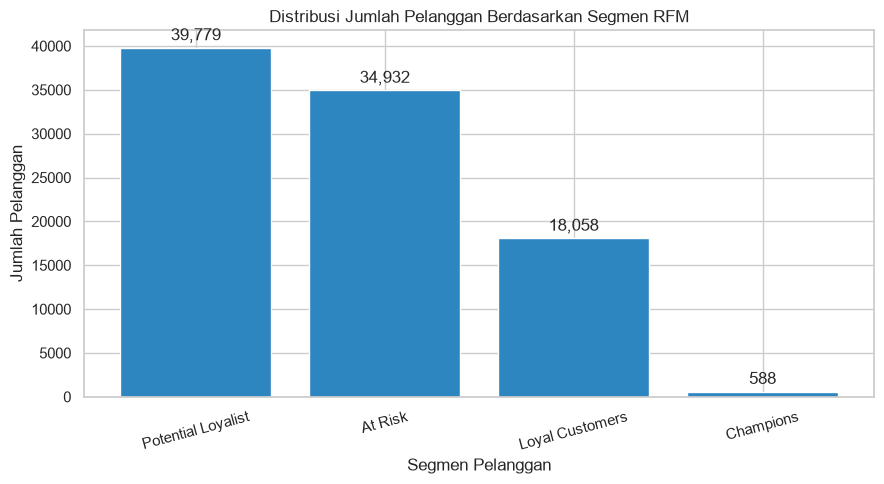

In [44]:
segment_counts = rfm_df['segment'].value_counts()

plt.figure(figsize=(9, 5))
bars = plt.bar(
    segment_counts.index,
    segment_counts.values,
    color='#2E86C1'
)

plt.title('Distribusi Jumlah Pelanggan Berdasarkan Segmen RFM')
plt.xlabel('Segmen Pelanggan')
plt.ylabel('Jumlah Pelanggan')
plt.xticks(rotation=15)

# Menampilkan jumlah pelanggan di atas setiap batang
plt.bar_label(bars, fmt='{:,.0f}', padding=3)

plt.tight_layout()
plt.show()

**Interpretasi Visualisasi Distribusi Segmen RFM**

Grafik menunjukkan bahwa segmen *Potential Loyalist* memiliki jumlah pelanggan terbanyak, yaitu 39.779 pelanggan, sedangkan segmen *Champions* memiliki jumlah paling sedikit, yaitu 588 pelanggan. Segmen *At Risk* juga mencakup jumlah pelanggan yang cukup besar, yakni 34.932 pelanggan, sementara *Loyal Customers* berjumlah 18.058 pelanggan.

Distribusi tersebut menunjukkan bahwa jumlah pelanggan tidak tersebar secara merata pada keempat segmen. Berdasarkan hasil ini, bisnis dapat mempertimbangkan strategi untuk mendorong pembelian berulang pada segmen *Potential Loyalist* dan mengaktifkan kembali pelanggan pada segmen *At Risk*. Pelanggan *Loyal Customers* dan *Champions* dapat menjadi sasaran strategi retensi yang disesuaikan dengan karakteristik masing-masing kelompok.

Namun, grafik ini hanya menunjukkan jumlah pelanggan, bukan besarnya kontribusi pendapatan atau efektivitas strategi pemasaran setiap segmen. Oleh karena itu, analisis lanjutan dapat membandingkan rata-rata Recency, Frequency, dan Monetary pada masing-masing segmen agar rekomendasi bisnis menjadi lebih terarah.

**Insight:** (Opsional)

- Analisis RFM dilakukan terhadap 93.357 pelanggan berdasarkan data pesanan delivered. Recency mengukur jarak waktu sejak pembelian terakhir, Frequency mengukur jumlah transaksi, dan Monetary mengukur total nilai pembayaran pelanggan.
- Hasil segmentasi menunjukkan 39.779 pelanggan berada pada segmen `Potential Loyalist`, 34.932 pada segmen `At Risk`, 18.058 pada segmen `Loyal Customers`, dan 588 pada segmen `Champions`.
- `Potential Loyalist` merupakan segmen terbesar. Kelompok ini dapat menjadi sasaran program engagement dan insentif pembelian ulang untuk mendorong terbentuknya loyalitas.
- Jumlah pelanggan `At Risk` juga cukup besar sehingga strategi reaktivasi dan retensi layak dipertimbangkan untuk mendorong pelanggan kembali bertransaksi.
- Segmen `Loyal Customers` dan `Champions` dapat dipertahankan melalui program loyalitas, benefit eksklusif, atau komunikasi yang relevan dengan riwayat pembelian mereka.
- Segmentasi ini menggunakan aturan scoring RFM, bukan algoritma machine learning. Oleh karena itu, hasilnya merupakan pengelompokan berbasis aturan yang dapat membantu menyusun strategi pelanggan, bukan prediksi pasti tentang perilaku pembelian di masa mendatang.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pada periode September 2016–Agustus 2017, kategori bed_bath_table menghasilkan revenue tertinggi sebesar BRL 254.923,81, diikuti health_beauty sebesar BRL 247.095,92 dan sports_leisure sebesar BRL 218.736,48. Revenue bulanan mencapai puncak pada Agustus 2017 sebesar BRL 549.731,25. Hasil ini menunjukkan bahwa ketiga kategori tersebut merupakan kandidat prioritas untuk evaluasi stok dan strategi pemasaran.
- **Conclusion pertanyaan 2:** Pesanan yang terlambat memiliki rata-rata review score 2,32, sedangkan pesanan yang tepat waktu memiliki rata-rata 4,28. Terdapat perbedaan rata-rata sebesar sekitar 1,96 poin. Secara deskriptif, keterlambatan pengiriman berkaitan dengan review score yang lebih rendah, meskipun analisis ini tidak membuktikan hubungan sebab-akibat.

**Rekomendasi Action Item:**

- Marketing dan Procurement: Evaluasi ketersediaan stok dan strategi promosi untuk kategori bed_bath_table, health_beauty, dan sports_leisure. Gunakan tren revenue bulanan sebagai salah satu masukan untuk perencanaan, bukan sebagai jaminan bahwa pola yang sama akan selalu berulang.

- Logistik: Pantau tingkat keterlambatan pengiriman dan evaluasi proses pengiriman berdasarkan seller, kurir, serta akurasi estimasi waktu. Lakukan pemantauan perubahan review score setelah perbaikan untuk menilai apakah pengalaman pelanggan ikut membaik.

- Customer Relationship Management (CRM): Rancang program retensi untuk pelanggan At Risk, program engagement untuk Potential Loyalist, dan program loyalitas untuk Loyal Customers serta Champions. Evaluasi efektivitasnya menggunakan metrik pembelian ulang, frekuensi transaksi, dan nilai pembelian.

## Menyimpan main_data.csv

In [45]:

dashboard_sales_df = order_items_cat_df.merge(
    orders_df[
        ['order_id', 'order_purchase_timestamp', 'order_status']
    ],
    on='order_id',
    how='inner'
)

dashboard_sales_df = dashboard_sales_df[
    dashboard_sales_df['order_status'] == 'delivered'
].copy()

main_data_df = dashboard_sales_df.merge(
    delivery_review_df[
        ['order_id', 'is_late', 'review_score']
    ],
    on='order_id',
    how='left'
)

main_data_df.to_csv('main_data.csv', index=False)

print("Rentang tanggal:",
      main_data_df['order_purchase_timestamp'].min(),
      "sampai",
      main_data_df['order_purchase_timestamp'].max())
print("Jumlah baris:", len(main_data_df))
print("Jumlah order unik:", main_data_df['order_id'].nunique())


Rentang tanggal: 2016-09-15 12:16:38 sampai 2018-08-29 15:00:37
Jumlah baris: 109047
Jumlah order unik: 95146


In [46]:

print("Status pesanan:")
print(main_data_df["order_status"].value_counts(dropna=False))

print("\nReview score per order:")
print(
    main_data_df.groupby("order_id")["review_score"]
    .nunique()
    .value_counts()
)

print("\nDuplikasi baris per order:")
print(
    main_data_df.groupby("order_id").size().describe()
)


Status pesanan:
order_status
delivered    109047
Name: count, dtype: int64

Review score per order:
review_score
0    52795
1    42237
2      114
Name: count, dtype: int64

Duplikasi baris per order:
count    95146.000000
mean         1.146102
std          0.549987
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         22.000000
dtype: float64


In [47]:

review_check = (
    main_data_df
    .dropna(subset=["review_score"])
    .groupby("order_id")["review_score"]
    .nunique()
)

orders_multiple_reviews = review_check[review_check > 1].index

main_data_df[
    main_data_df["order_id"].isin(orders_multiple_reviews)
][["order_id", "review_score", "is_late"]].head(20)


,order_id,review_score,is_late
1081,029863af4b968de1e5d6a82782e662f5,5.0,False
1082,029863af4b968de1e5d6a82782e662f5,4.0,False
2113,04f1827088d972a62224f5203a071500,1.0,False
2114,04f1827088d972a62224f5203a071500,5.0,False
2421,059bbeb3477ed66fd7e670c3f879009a,5.0,False
2422,059bbeb3477ed66fd7e670c3f879009a,2.0,False
3757,08bf75dcf867b9f13026785053e87052,5.0,False
3758,08bf75dcf867b9f13026785053e87052,3.0,False
8814,14d35062b86c2e1f69376af68e9e2a1e,4.0,False
8815,14d35062b86c2e1f69376af68e9e2a1e,5.0,False


## Dashboard Streamlit

In [48]:
import os

os.makedirs('dashboard_data', exist_ok=True)

print("Folder dashboard_data berhasil dibuat!")

Folder dashboard_data berhasil dibuat!


In [51]:
%%writefile dashboard_data/dashboard.py

import pandas as pd
import matplotlib.pyplot as plt
import streamlit as st
from pathlib import Path

# =========================
# CONFIG
# =========================
st.set_page_config(
    page_title="E-Commerce Dashboard",
    page_icon="📊",
    layout="wide"
)

# =========================
# LOAD DATA
# =========================
@st.cache_data
def load_data():
    data_path = Path(__file__).resolve().parent / "main_data.csv"
    df = pd.read_csv(data_path)
    df["order_purchase_timestamp"] = pd.to_datetime(
        df["order_purchase_timestamp"]
    )
    return df


main_df = load_data()

# =========================
# TITLE
# =========================
st.title("📊 E-Commerce Public Dataset Dashboard")

st.markdown(
    """
    Dashboard interaktif untuk menganalisis:
    - kontribusi revenue berdasarkan kategori produk,
    - tren revenue bulanan,
    - hubungan keterlambatan pengiriman dengan review pelanggan.
    """
)

# =========================
# SIDEBAR FILTER
# =========================
st.sidebar.header("🔎 Filter")

min_date = main_df["order_purchase_timestamp"].min().date()
max_date = main_df["order_purchase_timestamp"].max().date()

date_range = st.sidebar.date_input(
    "Rentang Tanggal",
    value=(min_date, max_date),
    min_value=min_date,
    max_value=max_date
)

# Pastikan user memilih dua tanggal
if len(date_range) == 2:

    start_date = pd.Timestamp(date_range[0])
    end_date = pd.Timestamp(date_range[1]) + pd.Timedelta(days=1)

    filtered_df = main_df[
        (main_df["order_purchase_timestamp"] >= start_date)
        & (main_df["order_purchase_timestamp"] < end_date)
    ]

else:
    filtered_df = main_df.copy()


# =========================
# KPI
# =========================
col1, col2, col3 = st.columns(3)

with col1:
    st.metric(
        "Total Revenue",
        f"BRL {filtered_df['price'].sum():,.2f}"
    )

with col2:
    st.metric(
        "Total Pesanan",
        f"{filtered_df['order_id'].nunique():,}"
    )

with col3:
    st.metric(
        "Total Produk Terjual",
        f"{len(filtered_df):,}"
    )


st.divider()


# =========================
# PERTANYAAN 1
# =========================
st.header(
    "1️⃣ Kategori Produk dengan Revenue Tertinggi"
)

revenue_per_category = (
    filtered_df
    .groupby("product_category_name_english")["price"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

col1, col2 = st.columns(2)

# ---- Bar chart ----
with col1:

    fig1, ax1 = plt.subplots(figsize=(8, 6))

    ax1.barh(
        revenue_per_category.index[::-1],
        revenue_per_category.values[::-1]
    )

    ax1.set_xlabel("Total Revenue (BRL)")
    ax1.set_ylabel("Kategori Produk")
    ax1.set_title("10 Kategori dengan Revenue Tertinggi")

    plt.tight_layout()

    st.pyplot(fig1)


# ---- Monthly revenue ----
with col2:

    monthly_revenue = (
        filtered_df
        .set_index("order_purchase_timestamp")
        .resample("ME")["price"]
        .sum()
    )

    fig2, ax2 = plt.subplots(figsize=(8, 6))

    ax2.plot(
        monthly_revenue.index,
        monthly_revenue.values,
        marker="o"
    )

    ax2.set_title("Tren Revenue Bulanan")
    ax2.set_xlabel("Bulan")
    ax2.set_ylabel("Revenue (BRL)")

    plt.xticks(rotation=45)
    plt.tight_layout()

    st.pyplot(fig2)


# =========================
# PERTANYAAN 2
# =========================
st.divider()

st.header(
    "2️⃣ Keterlambatan Pengiriman vs Review Score"
)

review_data = (
    filtered_df
    .dropna(subset=["review_score", "is_late"])
    .drop_duplicates(subset=["order_id"])
)

if len(review_data) > 0:

    avg_review = (
        review_data
        .groupby("is_late")["review_score"]
        .mean()
    )

    labels = [
        "Tepat Waktu" if not value else "Terlambat"
        for value in avg_review.index
    ]

    fig3, ax3 = plt.subplots(figsize=(7, 5))

    bars = ax3.bar(
        labels,
        avg_review.values
    )

    ax3.set_ylim(0, 5)
    ax3.set_ylabel("Rata-rata Review Score")
    ax3.set_title(
        "Rata-rata Review Score berdasarkan Ketepatan Pengiriman"
    )

    for bar in bars:

        height = bar.get_height()

        ax3.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.05,
            f"{height:.2f}",
            ha="center"
        )

    plt.tight_layout()

    st.pyplot(fig3)

else:

    st.warning(
        "Tidak ada data review pada rentang tanggal yang dipilih."
    )


# =========================
# DATA PREVIEW
# =========================
st.divider()

with st.expander("📄 Lihat Data"):

    st.dataframe(
        filtered_df,
        use_container_width=True
    )


# =========================
# FOOTER
# =========================
st.caption(
    "Dibuat untuk submission akhir "
    "Belajar Fundamental Analisis Data - Dicoding"
)

Writing dashboard_data/dashboard.py


In [50]:

import os
import pandas as pd

# ==========================================
# 1. MENENTUKAN LOKASI DATA
# ==========================================

BASE_DIR = "dashboard_data"

DATA_DIR = "data"

# Membaca dataset
main_data = pd.read_csv("main_data.csv")

orders = pd.read_csv(os.path.join(DATA_DIR, "orders_dataset.csv"))
customers = pd.read_csv(os.path.join(DATA_DIR, "customers_dataset.csv"))

# Mengubah format tanggal
main_data["order_purchase_timestamp"] = pd.to_datetime(
    main_data["order_purchase_timestamp"]
)

orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"]
)

# ==========================================
# 2. MENAMBAHKAN CUSTOMER UNIQUE ID
# ==========================================

customer_mapping = (
    orders[["order_id", "customer_id"]]
    .merge(
        customers[["customer_id", "customer_unique_id"]],
        on="customer_id",
        how="left",
        validate="many_to_one"
    )
)

main_data = main_data.merge(
    customer_mapping[["order_id", "customer_unique_id"]],
    on="order_id",
    how="left",
    validate="many_to_one"
)

# Menyimpan data utama
main_data.to_csv(
    os.path.join(BASE_DIR, "main_data.csv"),
    index=False
)

print("Main data berhasil dibuat:", main_data.shape)

# ==========================================
# 3. MEMBUAT MONTHLY SALES
# ==========================================

delivered_data = main_data[
    main_data["order_status"] == "delivered"
].copy()

delivered_data["month"] = (
    delivered_data["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

monthly_sales = (
    delivered_data
    .groupby("month", as_index=False)
    .agg(total_sales=("price", "sum"))
)

monthly_sales.to_csv(
    os.path.join(BASE_DIR, "monthly_sales.csv"),
    index=False
)

# ==========================================
# 4. MEMBUAT CATEGORY SALES
# ==========================================

delivered_data["product_category_name_english"] = (
    delivered_data["product_category_name_english"]
    .fillna("Unclassified")
)

category_sales = (
    delivered_data
    .groupby("product_category_name_english", as_index=False)
    .agg(total_sales=("price", "sum"))
    .sort_values("total_sales", ascending=False)
)

category_sales.to_csv(
    os.path.join(BASE_DIR, "category_sales.csv"),
    index=False
)

# ==========================================
# 5. MEMBUAT DATA RFM
# ==========================================

# Menghitung total transaksi per pesanan
order_sales = (
    delivered_data
    .groupby("order_id", as_index=False)
    .agg(
        monetary=("price", "sum"),
        order_date=("order_purchase_timestamp", "min")
    )
)

# Menghubungkan transaksi dengan identitas pelanggan
rfm_data = order_sales.merge(
    customer_mapping[["order_id", "customer_unique_id"]],
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Tanggal acuan untuk menghitung Recency
snapshot_date = rfm_data["order_date"].max() + pd.Timedelta(days=1)

# Menghitung Recency, Frequency, Monetary
rfm = (
    rfm_data
    .groupby("customer_unique_id")
    .agg(
        Recency=("order_date", lambda x: (snapshot_date - x.max()).days),
        Frequency=("order_id", "nunique"),
        Monetary=("monetary", "sum")
    )
    .reset_index()
)

# ==========================================
# 6. MEMBERIKAN SKOR RFM
# ==========================================

# Menggunakan rank agar pembagian kuintil tetap berjalan
# meskipun terdapat banyak nilai yang sama.

rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# ==========================================
# 7. MENENTUKAN SEGMEN PELANGGAN
# ==========================================

def classify_customer(row):

    r = row["R_Score"]
    f = row["F_Score"]
    m = row["M_Score"]

    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"

    elif f >= 4 and m >= 3:
        return "Loyal Customers"

    elif r >= 4 and f >= 2:
        return "Potential Loyalists"

    elif r <= 2 and f >= 3:
        return "At Risk"

    elif r <= 2 and f <= 2:
        return "Hibernating"

    else:
        return "Others"


rfm["segment"] = rfm.apply(classify_customer, axis=1)

# Menyimpan seluruh hasil RFM
rfm.to_csv(
    os.path.join(BASE_DIR, "rfm_data.csv"),
    index=False
)

# Membuat ringkasan jumlah pelanggan per segmen
segment_data = (
    rfm.groupby("segment")
    .agg(customer_count=("customer_unique_id", "count"))
    .reset_index()
    .sort_values("customer_count", ascending=False)
)

segment_data.to_csv(
    os.path.join(BASE_DIR, "segment_data.csv"),
    index=False
)

# ==========================================
# 8. MENAMPILKAN HASIL
# ==========================================

print("\nSELURUH FILE DASHBOARD BERHASIL DIBUAT!")

print("\n1. Monthly Sales")
display(monthly_sales.head())

print("\n2. Category Sales")
display(category_sales.head())

print("\n3. RFM Data")
display(rfm.head())

print("\n4. Customer Segmentation")
display(segment_data)

print("\nLokasi file:")
for file in os.listdir(BASE_DIR):
    print("-", file)


Main data berhasil dibuat: (109047, 14)

SELURUH FILE DASHBOARD BERHASIL DIBUAT!

1. Monthly Sales


,month,total_sales
0,2016-09,134.97
1,2016-10,40259.22
2,2016-12,10.90
3,2017-01,110969.75
4,2017-02,226962.29



2. Category Sales


,product_category_name_english,total_sales
44,health_beauty,1236083.14
71,watches_gifts,1166400.87
8,bed_bath_table,1034003.35
66,sports_leisure,958531.19
16,computers_accessories,891716.79



3. RFM Data


,customer_unique_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,segment
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,129.90,4,1,4,Others
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,18.90,4,1,1,Others
2,0000f46a3911fa3c0805444483337064,537,1,69.00,1,1,2,Hibernating
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99,2,1,1,Hibernating
4,0004aac84e0df4da2b147fca70cf8255,288,1,180.00,2,1,5,Hibernating



4. Customer Segmentation


,segment,customer_count
4,Others,21194
5,Potential Loyalists,20310
3,Loyal Customers,16239
2,Hibernating,14779
0,At Risk,13208
1,Champions,6368



Lokasi file:
- category_sales.csv
- main_data.csv
- monthly_sales.csv
- rfm_data.csv
- segment_data.csv
